|特征来源|列名|含义说明|
|:-:|:-:|:-:|
|患者编号|id||
|生理指标|age|患者年龄，单位`天(day)`|
|生理指标|height|患者身高，单位`cm`|
|生理指标|weight|患者体重，单位`kg`|
|生理指标|gender|患者性别，`1`为女性，`2`为男性|
|医疗指标|ap_hi|收缩压(心脏收缩时的动脉血压最高值)|
|医疗指标|ap_lo|舒张压(心脏舒张时的动脉血压最低值)|
|医疗指标|cholesterol|胆固醇水平，`1`为正常, `2`为超出正常水平, `3`为大量超出正常水平|
|医疗指标|gluc|血糖浓度(血液中的葡萄糖含量)，`1`为正常, `2`为超出正常水平, `3`为大量超出正常水平|
|主观信息|smoke|患者是否经常吸烟，`1`代表经常吸烟，`0`代表不经常吸烟|
|主观信息|alco|患者是否经常饮酒，`1`代表经常饮酒，`0`代表不经常饮酒|
|主观信息|active|患者是否经常运动，`1`代表经常运动，`0`代表不经常运动|
|患病情况|cardio|当患有心血管疾病时，目标类别`cardio`为1，否则`cardio`为0|

读取

In [94]:
# 导入需要的工具包
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.family']='SimHei' #中文显示
plt.rcParams['axes.unicode_minus']=False #负号显示
plt.rcParams['font.weight']=30

data = pd.read_csv("cardio_train.csv")
data.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [95]:
data.shape

(70000, 13)

In [96]:
data.columns

Index(['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio'],
      dtype='object')

In [97]:
data.dtypes

id               int64
age              int64
gender           int64
height           int64
weight         float64
ap_hi            int64
ap_lo            int64
cholesterol      int64
gluc             int64
smoke            int64
alco             int64
active           int64
cardio           int64
dtype: object

In [98]:
data.info() #查看数据的基本信息

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


In [99]:
data.describe(include='all')

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,49972.419900,19468.865814,1.349571,164.359229,74.205690,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700
std,28851.302323,2467.251667,0.476838,8.210126,14.395757,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003
min,0.000000,10798.000000,1.000000,55.000000,10.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,25006.750000,17664.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,50001.500000,19703.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,74889.250000,21327.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,99999.000000,23713.000000,2.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


<ipython-input-100-53674a537d30>:4: MatplotlibDeprecationWarning: Passing non-integers as three-element position specification is deprecated since 3.3 and will be removed two minor releases later.
  plt.subplot("22"+str(i+1))


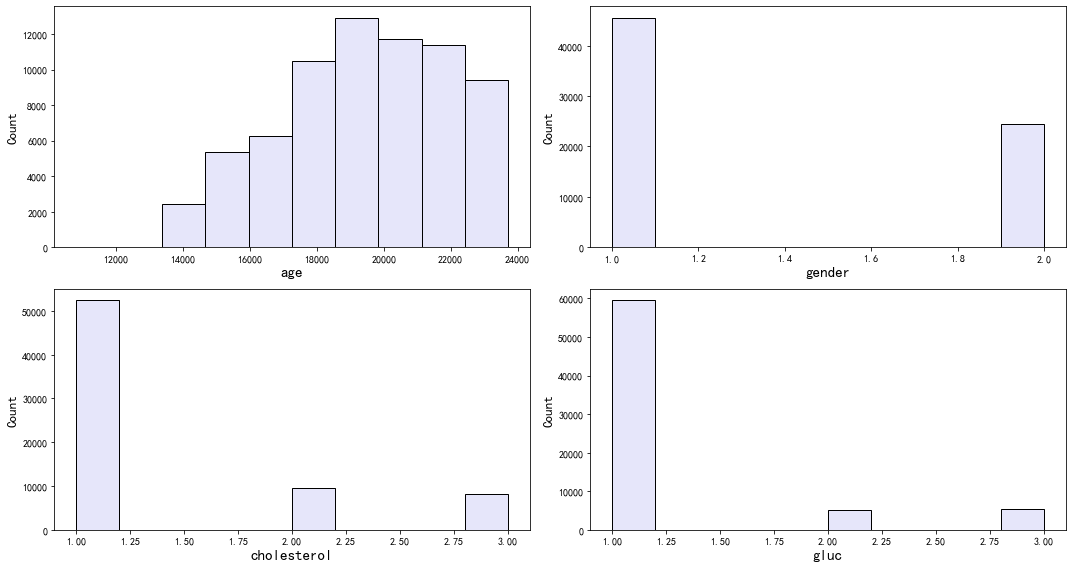

In [100]:
col = data.columns[[1,2,7,8]].tolist()
fig,ax = plt.subplots(2,2,figsize = (15,8))
for i in range(0,len(col)):
    plt.subplot("22"+str(i+1))
    plt.hist(data[col[i]],facecolor='lavender',edgecolor="black")
    plt.xlabel(col[i],fontsize = 15)
    plt.ylabel("Count",fontsize = 13)  
plt.tight_layout()
plt.show()

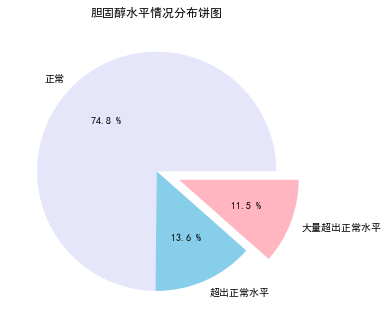

In [101]:
# #饼图
y=data['cholesterol'].value_counts()
plt.title("胆固醇水平情况分布饼图")
plt.pie(y, autopct='%.1f %%',colors=['lavender','skyblue','lightpink'],explode=[0,0,0.2],labels=['正常', '超出正常水平','大量超出正常水平'])
plt.show()

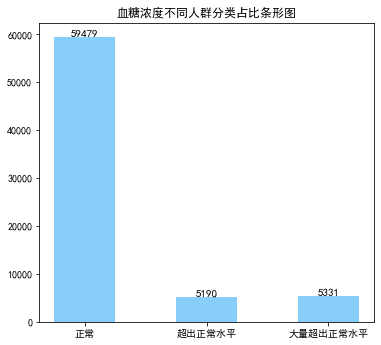

In [102]:
#条形图
plt.rcParams['figure.figsize'] = (6,5.5)
x=['正常', '超出正常水平','大量超出正常水平']
y=data['gluc'].value_counts().sort_index()
plt.title("血糖浓度不同人群分类占比条形图",fontsize=12)
plt.bar(x,y,color='lightskyblue',width=0.5)
for a,b in zip(x,y):   #柱子上的数字显示
    plt.text(a,b,'%.f'%b,ha='center',va='baseline',fontsize=11);
plt.show()

预处理

In [103]:
data['age'] = round(data['age']/365).astype(int)

In [104]:
data['age'].value_counts().sort_index()

30       4
39     409
40    2700
41     766
42    2624
43     690
44    2837
45     757
46    2955
47     754
48    3194
49    1059
50    5267
51    1348
52    5303
53    1407
54    5988
55    1498
56    6031
57    1452
58    5702
59    1355
60    5465
61    1221
62    3926
63    1016
64    3920
65     352
Name: age, dtype: int64

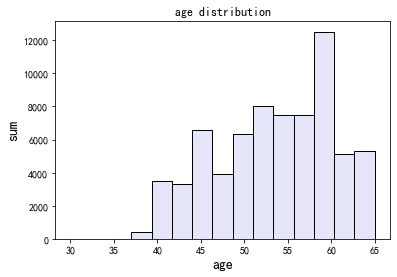

In [105]:
# #直方图
fig = plt.subplots(figsize = (6,4))

plt.hist(data['age'],facecolor='lavender',edgecolor="black",bins=15)
plt.title("age distribution")
plt.xlabel("age",fontsize=14)#年龄
plt.ylabel("sum",fontsize=14)#总人数
plt.show()

<ipython-input-106-b1e07ee6b17c>:4: MatplotlibDeprecationWarning: Passing non-integers as three-element position specification is deprecated since 3.3 and will be removed two minor releases later.
  plt.subplot('22'+str(i+1))
D:\anaconda\lib\site-packages\seaborn\distributions.py:2551: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
<ipython-input-106-b1e07ee6b17c>:4: MatplotlibDeprecationWarning: Passing non-integers as three-element position specification is deprecated since 3.3 and will be removed two minor releases later.
  plt.subplot('22'+str(i+1))
D:\anaconda\lib\site-packages\seaborn\distributions.py:2551: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a fig

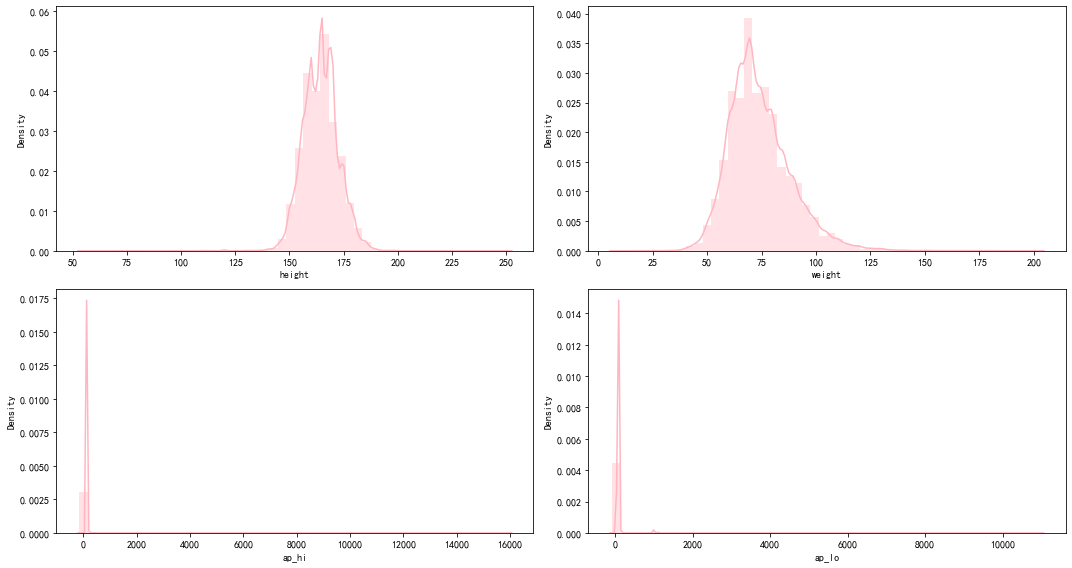

In [106]:
col = data.columns[[3,4,5,6]].tolist()
fig,ax = plt.subplots(2,2,figsize = (15,8))
for i in range(0,len(col)):
    plt.subplot('22'+str(i+1))
    x = data[col[i]]
    sns.distplot(x,color = 'lightpink') 
plt.tight_layout()
plt.show()

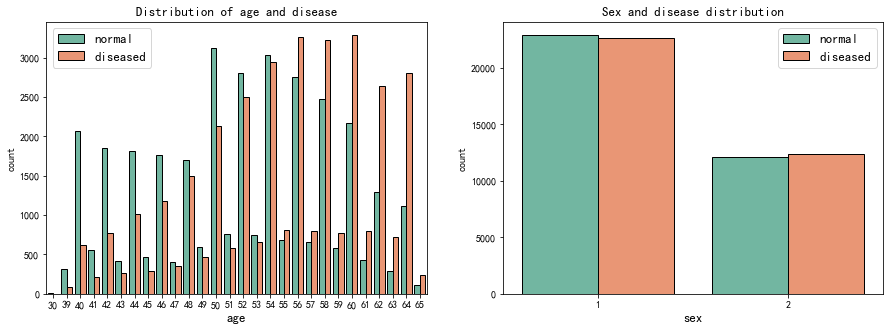

In [107]:
fig,[ax1,ax2] = plt.subplots(1,2,figsize=(15,5))

sns.countplot(x='age', hue='cardio', data = data, palette="Set2",ax=ax1,edgecolor="black")
sns.countplot(x='gender', hue='cardio', data = data, palette="Set2",ax=ax2,edgecolor="black")

ax1.set_xlabel('age',fontsize = 13)
ax2.set_xlabel('sex',fontsize = 13)
ax1.set_title('Distribution of age and disease',fontsize = 13)
ax2.set_title('Sex and disease distribution',fontsize = 13)
ax1.legend(['normal','diseased'],fontsize = 13)
ax2.legend(['normal','diseased'],fontsize = 13)

plt.show()

异常数据处理

+ 我们已经将数据中的年龄字段由天转换为年，该数据集中患者年龄的取值区间为30-65岁，其中50-60岁的人数最多。
接下来我们处理身高和体重的异常值，数据中患者均为成年人，根据生活常识剔除异常值,身高低于140cm且体重低于40kg则认为是异常值，按照这个方法从数据中剔除异常数据。

In [144]:
data = data[(data['height']>=140)&(data['weight']>=40)]
data.shape

(68587, 21)

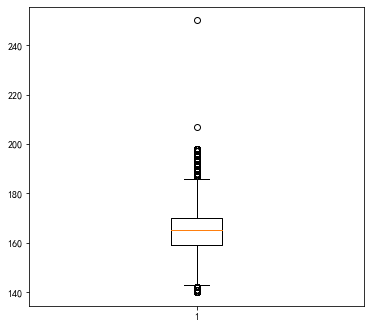

In [145]:
# #箱线图
x = data['height']

plt.boxplot(x)
plt.show()

通过身高和体重的限定，剔除了198个异常数据，接下来处理血压的异常数据。
血压的单位为千帕，1千帕=7.6mmHg，成人正常的收缩压为90 ~ 130mmHg，正常的舒张压为60 ~ 90mmHg。根据世界卫生组织规定，成人收缩压小于90mmHg则可确诊为低血压;90到130之间称为正常血压；130到140之间称为临界高血压；大于等于140mmHg称为高血压。如下所示：
+ 低血压：收缩压<90
+ 正常血压：90<=收缩压<130
+ 临界高血压：130<=收缩压<140
+ 高血压：140<=收缩压

考虑到高低血压的变化范围，我们将收缩压ap_hi变化区间限定为[60,250]，将舒张压ap_lo的变化区间限定为[30,180]。

In [110]:
data = data[(60<=data['ap_hi'])&(data['ap_hi']<=250)&(30<=data['ap_lo'])&(data['ap_lo']<=180)]
data.shape

(68587, 13)

通过血压变化的限定，我们又剔除了1215个异常数据。

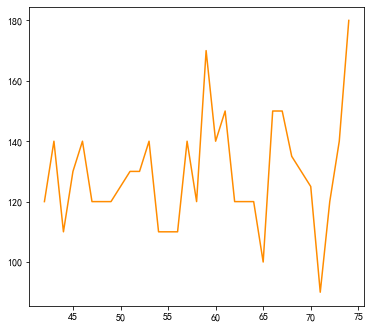

In [111]:
# #折线图
x=data['id'][30:60]
y=data['ap_hi'][30:60]
plt.plot(x, y,color='darkorange')
plt.show()

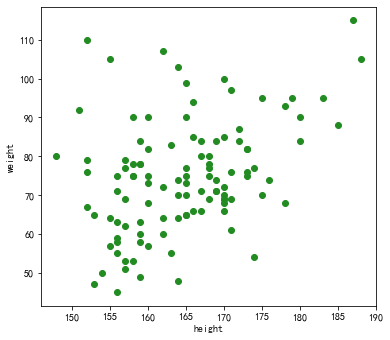

In [112]:
# #散点
plt.scatter(data["height"][20:130], data["weight"][20:130],color='forestgreen')
plt.xlabel("height")
plt.ylabel("weight")
plt.show()

In [113]:
data['BMI'] = data['weight'] / np.square(data['height']/100)
print(data.head())

   id  age  gender  height  weight  ap_hi  ap_lo  cholesterol  gluc  smoke  \
0   0   50       2     168    62.0    110     80            1     1      0   
1   1   55       1     156    85.0    140     90            3     1      0   
2   2   52       1     165    64.0    130     70            3     1      0   
3   3   48       2     169    82.0    150    100            1     1      0   
4   4   48       1     156    56.0    100     60            1     1      0   

   alco  active  cardio        BMI  
0     0       1       0  21.967120  
1     0       1       1  34.927679  
2     0       0       1  23.507805  
3     0       1       1  28.710479  
4     0       0       0  23.011177  


<Figure size 288x576 with 0 Axes>

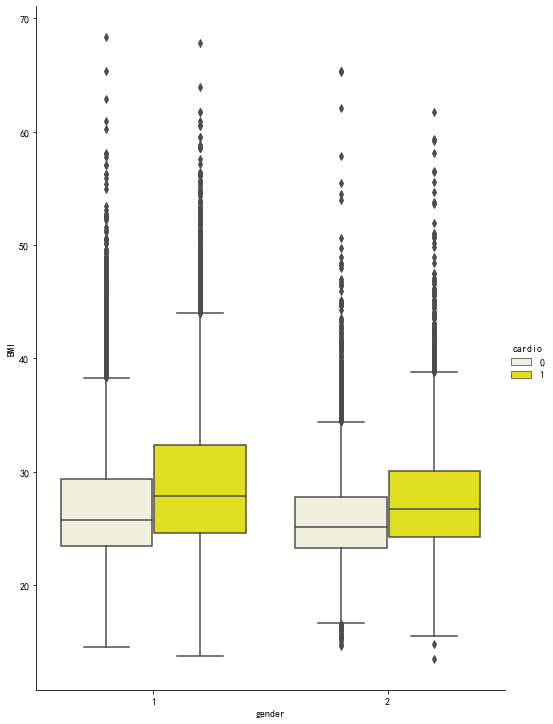

In [114]:
fig = plt.figure(figsize=(4,8))

sns.catplot(x="gender", y="BMI", hue="cardio", data=data, color = "yellow",kind="box",height=10, aspect=.7)

plt.show()

无缺失值

In [115]:
data.isnull().sum()

id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
BMI            0
dtype: int64

In [116]:
data.dropna() #删缺失值

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,BMI
0,0,50,2,168,62.0,110,80,1,1,0,0,1,0,21.967120
1,1,55,1,156,85.0,140,90,3,1,0,0,1,1,34.927679
2,2,52,1,165,64.0,130,70,3,1,0,0,0,1,23.507805
3,3,48,2,169,82.0,150,100,1,1,0,0,1,1,28.710479
4,4,48,1,156,56.0,100,60,1,1,0,0,0,0,23.011177
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,99993,53,2,168,76.0,120,80,1,1,1,0,1,0,26.927438
69996,99995,62,1,158,126.0,140,90,2,2,0,0,1,1,50.472681
69997,99996,52,2,183,105.0,180,90,3,1,0,1,0,1,31.353579
69998,99998,61,1,163,72.0,135,80,1,2,0,0,0,1,27.099251


冗余值处理

In [117]:
data.drop_duplicates() #去重

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,BMI
0,0,50,2,168,62.0,110,80,1,1,0,0,1,0,21.967120
1,1,55,1,156,85.0,140,90,3,1,0,0,1,1,34.927679
2,2,52,1,165,64.0,130,70,3,1,0,0,0,1,23.507805
3,3,48,2,169,82.0,150,100,1,1,0,0,1,1,28.710479
4,4,48,1,156,56.0,100,60,1,1,0,0,0,0,23.011177
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,99993,53,2,168,76.0,120,80,1,1,1,0,1,0,26.927438
69996,99995,62,1,158,126.0,140,90,2,2,0,0,1,1,50.472681
69997,99996,52,2,183,105.0,180,90,3,1,0,1,0,1,31.353579
69998,99998,61,1,163,72.0,135,80,1,2,0,0,0,1,27.099251


哑变量处理

In [118]:
# 选没有数量关系的数据，需进行哑变量处理，且选不包括y,选离散型数据

In [119]:
features=['gender','cholesterol','gluc','smoke','alco']
data=pd.get_dummies(data,columns=features)
data.columns

Index(['id', 'age', 'height', 'weight', 'ap_hi', 'ap_lo', 'active', 'cardio',
       'BMI', 'gender_1', 'gender_2', 'cholesterol_1', 'cholesterol_2',
       'cholesterol_3', 'gluc_1', 'gluc_2', 'gluc_3', 'smoke_0', 'smoke_1',
       'alco_0', 'alco_1'],
      dtype='object')

In [120]:
data.head()

,id,age,height,weight,ap_hi,ap_lo,active,cardio,BMI,gender_1,...,cholesterol_1,cholesterol_2,cholesterol_3,gluc_1,gluc_2,gluc_3,smoke_0,smoke_1,alco_0,alco_1
0,0,50,168,62.0,110,80,1,0,21.967120,0,...,1,0,0,1,0,0,1,0,1,0
1,1,55,156,85.0,140,90,1,1,34.927679,1,...,0,0,1,1,0,0,1,0,1,0
2,2,52,165,64.0,130,70,0,1,23.507805,1,...,0,0,1,1,0,0,1,0,1,0
3,3,48,169,82.0,150,100,1,1,28.710479,0,...,1,0,0,1,0,0,1,0,1,0
4,4,48,156,56.0,100,60,0,0,23.011177,1,...,1,0,0,1,0,0,1,0,1,0


corr()相关性

In [121]:
# data.corr()['cardio'].drop('cardio')
data.corr()

,id,age,height,weight,ap_hi,ap_lo,active,cardio,BMI,gender_1,...,cholesterol_1,cholesterol_2,cholesterol_3,gluc_1,gluc_2,gluc_3,smoke_0,smoke_1,alco_0,alco_1
id,1.000000,0.003061,-0.002774,-0.001680,0.001394,-0.000803,0.004190,0.003499,-0.000736,-0.002910,...,-0.004797,0.000684,0.005783,-0.002300,0.001296,0.001819,0.003220,-0.003220,-0.000522,0.000522
age,0.003061,1.000000,-0.086745,0.055851,0.208767,0.152900,-0.010740,0.239137,0.104412,0.023399,...,-0.130703,0.021945,0.154044,-0.088568,0.024477,0.095086,0.048224,-0.048224,0.029218,-0.029218
height,-0.002774,-0.086745,1.000000,0.309980,0.017053,0.034302,-0.009744,-0.012938,-0.194411,-0.523547,...,0.054970,-0.027891,-0.044754,0.022289,-0.014749,-0.015465,-0.196701,0.196701,-0.098527,0.098527
weight,-0.001680,0.055851,0.309980,1.000000,0.268233,0.248011,-0.017523,0.179728,0.867747,-0.156606,...,-0.137444,0.067350,0.114462,-0.120920,0.095251,0.068881,-0.066917,0.066917,-0.068009,0.068009
ap_hi,0.001394,0.208767,0.017053,0.268233,1.000000,0.697508,-0.001519,0.425187,0.267929,-0.061086,...,-0.191207,0.099335,0.153180,-0.101649,0.075646,0.062263,-0.026791,0.026791,-0.032181,0.032181
ap_lo,-0.000803,0.152900,0.034302,0.248011,0.697508,1.000000,-0.000203,0.335315,0.238298,-0.066690,...,-0.152743,0.071652,0.130631,-0.083327,0.060874,0.052161,-0.024626,0.024626,-0.042670,0.042670
active,0.004190,-0.010740,-0.009744,-0.017523,-0.001519,-0.000203,1.000000,-0.037492,-0.013529,-0.005884,...,-0.004971,-0.005455,0.012612,0.010184,-0.011027,-0.002839,-0.025198,0.025198,-0.025163,0.025163
cardio,0.003499,0.239137,-0.012938,0.179728,0.425187,0.335315,-0.037492,1.000000,0.191460,-0.007148,...,-0.205319,0.080285,0.192807,-0.091130,0.052617,0.070802,0.016360,-0.016360,0.008052,-0.008052
BMI,-0.000736,0.104412,-0.194411,0.867747,0.267929,0.238298,-0.013529,0.191460,1.000000,0.112019,...,-0.168502,0.081797,0.141155,-0.135000,0.104558,0.078659,0.033616,-0.033616,-0.017993,0.017993
gender_1,-0.002910,0.023399,-0.523547,-0.156606,-0.061086,-0.066690,-0.005884,-0.007148,0.112019,1.000000,...,-0.035603,0.017463,0.029632,-0.018957,0.005462,0.020133,0.338790,-0.338790,0.171324,-0.171324


<ipython-input-122-17e873a21a51>:12: DeprecationWarning: `np.bool` is a deprecated alias for the builtin `bool`. To silence this warning, use `bool` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.bool_` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  mask = np.zeros_like(corr, dtype=np.bool)


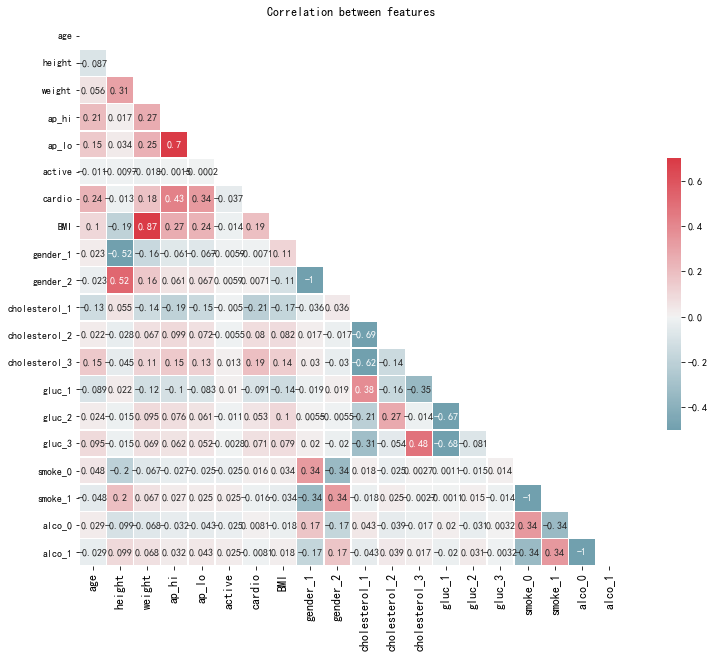

In [122]:
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['axes.unicode_minus']=False

selected_features = data.drop(['id'],axis = 1)
corr = selected_features.corr()

fig = plt.figure(figsize = (16,10))

cmap = sns.diverging_palette(220, 10, as_cmap=True)
mask = np.zeros_like(corr, dtype=np.bool)
mask[np.triu_indices_from(mask)] = True

# 绘制热力图
sns.heatmap(corr, mask=mask, cmap=cmap,vmin=-0.5,vmax=0.7, center=0,annot = True,
            square=True, linewidths=.5,cbar_kws={"shrink": .5});
plt.title("Correlation between features",fontsize = 12)

plt.xticks(rotation=90, fontsize=12)
plt.show()

In [123]:
y=data["cardio"]
x=data.drop("cardio",axis=1)

In [124]:
y.head()

0    0
1    1
2    1
3    1
4    0
Name: cardio, dtype: int64

In [125]:
x.head()

,id,age,height,weight,ap_hi,ap_lo,active,BMI,gender_1,gender_2,cholesterol_1,cholesterol_2,cholesterol_3,gluc_1,gluc_2,gluc_3,smoke_0,smoke_1,alco_0,alco_1
0,0,50,168,62.0,110,80,1,21.967120,0,1,1,0,0,1,0,0,1,0,1,0
1,1,55,156,85.0,140,90,1,34.927679,1,0,0,0,1,1,0,0,1,0,1,0
2,2,52,165,64.0,130,70,0,23.507805,1,0,0,0,1,1,0,0,1,0,1,0
3,3,48,169,82.0,150,100,1,28.710479,0,1,1,0,0,1,0,0,1,0,1,0
4,4,48,156,56.0,100,60,0,23.011177,1,0,1,0,0,1,0,0,1,0,1,0


In [126]:
x.shape

(68587, 20)

In [127]:
y.shape

(68587,)

In [128]:
from sklearn.preprocessing import MinMaxScaler #离差标准化
Scaler = MinMaxScaler().fit(x) #生成规则
x = Scaler.transform(x) #运用规则

In [129]:
x

array([[0.00000000e+00, 5.71428571e-01, 2.54545455e-01, ...,
        0.00000000e+00, 1.00000000e+00, 0.00000000e+00],
       [1.00001000e-05, 7.14285714e-01, 1.45454545e-01, ...,
        0.00000000e+00, 1.00000000e+00, 0.00000000e+00],
       [2.00002000e-05, 6.28571429e-01, 2.27272727e-01, ...,
        0.00000000e+00, 1.00000000e+00, 0.00000000e+00],
       ...,
       [9.99970000e-01, 6.28571429e-01, 3.90909091e-01, ...,
        0.00000000e+00, 0.00000000e+00, 1.00000000e+00],
       [9.99990000e-01, 8.85714286e-01, 2.09090909e-01, ...,
        0.00000000e+00, 1.00000000e+00, 0.00000000e+00],
       [1.00000000e+00, 7.42857143e-01, 2.72727273e-01, ...,
        0.00000000e+00, 1.00000000e+00, 0.00000000e+00]])

In [130]:
# from sklearn.preprocessing import StandardScaler # 标准差标准化
# scale = StandardScaler().fit(x_train) 
# x_train= scale.transform(x_train) 
# x_test = scale.transform(x_test)

数据集划分

In [131]:
from sklearn.model_selection import train_test_split
x_train, x_test,y_train, y_test = train_test_split(x, y,test_size=0.2, random_state=2)

In [132]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(54869, 20)
(13718, 20)
(54869,)
(13718,)


建模

In [135]:
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score

In [136]:
## 逻辑回归
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(penalty='l2',C=0.6,random_state = 42,solver='liblinear', class_weight="balanced").fit(x_train,y_train)
y_pred = lr.predict(x_test)
print('分类报告为：','\n', classification_report(y_test,y_pred))
print("The acc of randomforest is %.5f"%(accuracy_score(y_test,y_pred)))

分类报告为： 
               precision    recall  f1-score   support

           0       0.71      0.79      0.75      6966
           1       0.75      0.67      0.71      6752

    accuracy                           0.73     13718
   macro avg       0.73      0.73      0.73     13718
weighted avg       0.73      0.73      0.73     13718

The acc of randomforest is 0.72831


In [139]:
#随机森林
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators = 100, random_state = 42).fit(x_train,y_train)
y_pred = rf.predict(x_test)
print('分类报告为：','\n', classification_report(y_test,y_pred))
print("The acc of randomforest is %.5f"%(accuracy_score(y_test,y_pred)))

分类报告为： 
               precision    recall  f1-score   support

           0       0.71      0.75      0.73      6966
           1       0.73      0.69      0.71      6752

    accuracy                           0.72     13718
   macro avg       0.72      0.72      0.72     13718
weighted avg       0.72      0.72      0.72     13718

The acc of randomforest is 0.71884


In [140]:
## 梯度提升树
from sklearn.ensemble import GradientBoostingClassifier
gbdt = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1,max_depth=4, random_state=42).fit(x_train, y_train)
y_pred = gbdt.predict(x_test)
print('分类报告为：','\n', classification_report(y_test,y_pred))
print("The acc of randomforest is %.5f"%(accuracy_score(y_test,y_pred)))

分类报告为： 
               precision    recall  f1-score   support

           0       0.72      0.78      0.75      6966
           1       0.75      0.69      0.72      6752

    accuracy                           0.74     13718
   macro avg       0.74      0.74      0.73     13718
weighted avg       0.74      0.74      0.74     13718

The acc of randomforest is 0.73582


In [141]:
from sklearn.neighbors import KNeighborsClassifier
# 创建k近邻实例
neigh = KNeighborsClassifier(n_neighbors=10)
# k近邻模型拟合
neigh.fit(x_train,y_train)
# k近邻模型预测
y_pred = neigh.predict(x_test)
print('分类报告为：','\n', classification_report(y_test,y_pred))
print("The acc of randomforest is %.5f"%(accuracy_score(y_test,y_pred)))

D:\anaconda\lib\site-packages\sklearn\neighbors\_classification.py:189: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  mode, _ = stats.mode(_y[neigh_ind, k], axis=1)


分类报告为： 
               precision    recall  f1-score   support

           0       0.68      0.78      0.72      6966
           1       0.73      0.62      0.67      6752

    accuracy                           0.70     13718
   macro avg       0.70      0.70      0.70     13718
weighted avg       0.70      0.70      0.70     13718

The acc of randomforest is 0.70010


In [142]:
from sklearn.svm import SVC
svc = SVC(gamma='auto',random_state = 42).fit(x_train,y_train)
y_pred = svc.predict(x_test)
print('分类报告为：','\n', classification_report(y_test,y_pred))
print("The acc of randomforest is %.5f"%(accuracy_score(y_test,y_pred)))

分类报告为： 
               precision    recall  f1-score   support

           0       0.70      0.81      0.75      6966
           1       0.77      0.64      0.70      6752

    accuracy                           0.73     13718
   macro avg       0.73      0.73      0.73     13718
weighted avg       0.73      0.73      0.73     13718

The acc of randomforest is 0.72824


优化

In [54]:
from sklearn.model_selection importz GridSearchCV

In [55]:
# help(GridSearchCV)

In [56]:
from sklearn.ensemble import GradientBoostingClassifier

In [57]:
# help(GradientBoostingClassifier)

In [58]:
param_test1 = {'n_estimators':range (1,100,1)}
gsearch1 = GridSearchCV(estimator = GradientBoostingClassifier(learning_rate=0.1,
                                                               random_state=42),
                                    param_grid=param_test1,scoring='roc_auc',cv=5)
gsearch1.fit(x, y)
print(gsearch1.best_params_, gsearch1.best_score_)

{'n_estimators': 4} 0.7841643595083532


In [59]:
param_test1 = {'max_features' : ['auto', 'sqrt', 'log2']}
gsearch1 = GridSearchCV(estimator = GradientBoostingClassifier(n_estimators=4,
                                                               learning_rate=0.1,
                                                               random_state=42),
                                    param_grid=param_test1 ,scoring='roc_auc',cv=5)
gsearch1.fit(x,y)
print(gsearch1.best_params_, gsearch1.best_score_)

{'max_features': 'auto'} 0.7841643595083532


In [60]:
param_test1 = {'max_depth' : range(1,10,1)}
gsearch1 = GridSearchCV(estimator = GradientBoostingClassifier(n_estimators=4,
                                                               learning_rate=0.1,
                                                               random_state=42,
                                                               max_features='auto'),
                                    param_grid=param_test1 ,scoring='roc_auc',cv=5)
gsearch1.fit(x,y)
print(gsearch1.best_params_, gsearch1.best_score_)

{'max_depth': 3} 0.7841643595083532


In [ ]:
param_test1 = {'n_estimators':range (1,100,1),'max_features' : ['auto', 'sqrt', 'log2'],'max_depth' : range(1,10,1)}
gsearch1 = GridSearchCV(estimator = GradientBoostingClassifier(learning_rate=0.1,
                                                               random_state=42,),
                                    param_grid=param_test1 ,scoring='roc_auc',cv=5)
gsearch1.fit(x,y)
print(gsearch1.best_params_, gsearch1.best_score_)

In [143]:
## 梯度提升树
from sklearn.ensemble import GradientBoostingClassifier
gbdt = GradientBoostingClassifier(n_estimators=4,
                                  learning_rate=0.1,
                                  max_depth=3,
                                  random_state=42,
                                  max_features='auto').fit(x_train, y_train)
y_pred = gbdt.predict(x_test)
print('分类报告为：','\n', classification_report(y_test,y_pred))
print("The acc of randomforest is %.5f"%(accuracy_score(y_test,y_pred)))

分类报告为： 
               precision    recall  f1-score   support

           0       0.70      0.79      0.75      6966
           1       0.75      0.65      0.70      6752

    accuracy                           0.72     13718
   macro avg       0.73      0.72      0.72     13718
weighted avg       0.73      0.72      0.72     13718

The acc of randomforest is 0.72467
